# Capítulo 3 · Matplotlib desde cero

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/lectures/chapter_03/03_matplotlib.ipynb)

**Visualización para Machine Learning**

---

### ¿Por qué visualizar?

Un modelo de ML es tan bueno como tu comprensión de los datos y de su comportamiento. Visualizar te permite:

- 🔍 **Explorar los datos** antes de modelar: distribuciones, valores atípicos, relaciones entre variables.
- 📉 **Diagnosticar el entrenamiento**: ¿la pérdida baja? ¿hay *overfitting*?
- 🎯 **Evaluar el modelo**: matriz de confusión, predicciones vs. valores reales, fronteras de decisión.
- 🗣️ **Comunicar resultados** a otras personas.

**Matplotlib** es la librería de visualización de referencia en Python. Otras como *seaborn* o la función `.plot()` de *pandas* están construidas encima de ella.

### 🎯 Objetivos
1. Entender la anatomía de una figura (`Figure` y `Axes`).
2. Crear los gráficos básicos con matplotlib: líneas, dispersión y barras.
3. Combinar varios gráficos con `subplots` y personalizarlos.
4. Explorar un DataFrame con **seaborn**: distribuciones, comparaciones y correlaciones.
5. Construir los **gráficos esenciales de ML**: curvas de aprendizaje, fronteras de decisión, matriz de confusión, *overfitting*…

### 📚 Índice
1. Primer gráfico
2. Las dos formas de usar matplotlib: `pyplot` vs. orientada a objetos
3. Personalizar: colores, estilos, marcadores, leyendas
4. Tipos de gráficos fundamentales
5. Varios gráficos en una figura: `subplots`
6. Imágenes y matrices: `imshow`
7. **Seaborn**: gráficos estadísticos en pocas líneas
8. **Gráficos esenciales en Machine Learning**
9. Estilos y guardar figuras
10. Chuleta resumen

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Gráficos un poco más grandes y nítidos por defecto
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["figure.dpi"] = 100

rng = np.random.default_rng(42)

> 💡 La convención universal es `import matplotlib.pyplot as plt`. En Jupyter los gráficos se muestran automáticamente debajo de la celda.

---
## 1. Primer gráfico

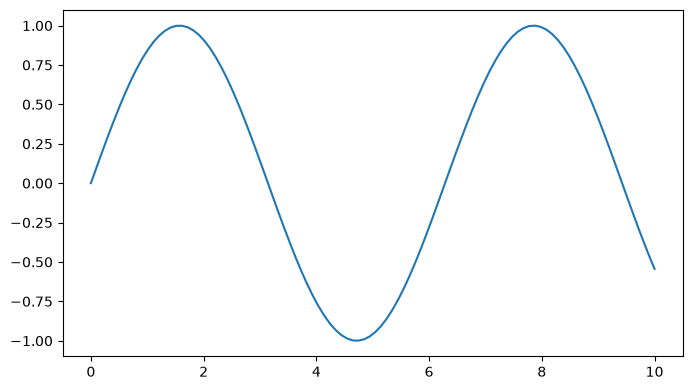

In [2]:
x = np.linspace(0, 10, 100)   # 100 puntos entre 0 y 10
y = np.sin(x)

plt.plot(x, y)
plt.show()

Así de simple: le pasamos los valores de `x` y de `y`, y matplotlib une los puntos con líneas. Ahora añadamos lo mínimo que todo gráfico debería tener: **título y etiquetas en los ejes**.

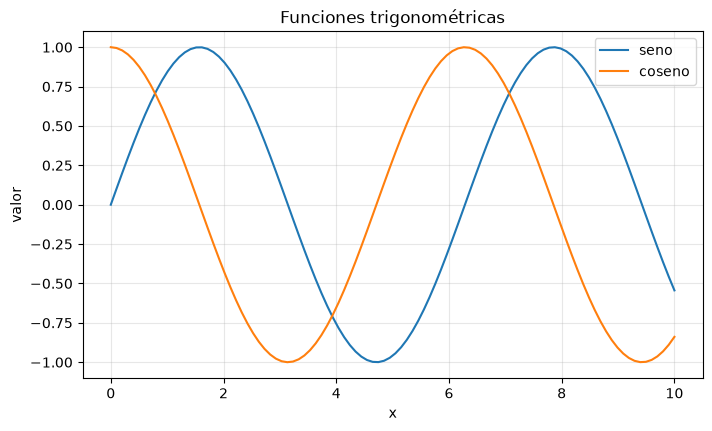

In [3]:
plt.plot(x, np.sin(x), label="seno")
plt.plot(x, np.cos(x), label="coseno")
plt.title("Funciones trigonométricas")
plt.xlabel("x")
plt.ylabel("valor")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

> ✅ **Regla de oro**: un gráfico sin título, sin etiquetas en los ejes o sin leyenda (cuando hay varias series) es un gráfico incompleto.

---
## 2. Las dos formas de usar matplotlib

### Anatomía de una figura
- **`Figure`**: el "lienzo" completo, la ventana o imagen final.
- **`Axes`**: cada área de dibujo dentro de la figura (con sus ejes, título, etc.). Una figura puede tener varios `Axes`.

```
┌──────────────── Figure ────────────────┐
│  ┌──── Axes ────┐   ┌──── Axes ────┐   │
│  │   título     │   │   título     │   │
│  │   gráfico    │   │   gráfico    │   │
│  │ ejes x / y   │   │ ejes x / y   │   │
│  └──────────────┘   └──────────────┘   │
└────────────────────────────────────────┘
```

### Interfaz `pyplot` (`plt.xxx`)
Lo que hicimos arriba. Rápida para gráficos sencillos, pero matplotlib decide "en qué Axes" dibujar.

### Interfaz orientada a objetos (`fig, ax`) ⭐ recomendada
Creamos explícitamente la figura y los ejes y llamamos a los métodos sobre `ax`. Es más clara y **es la única forma cómoda de trabajar con varios gráficos**.

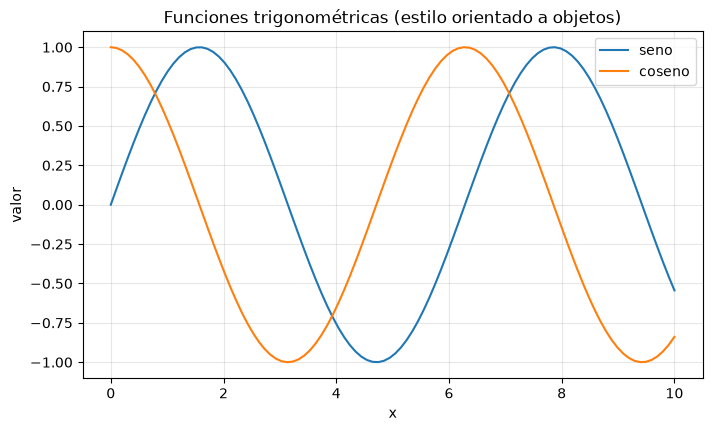

In [4]:
fig, ax = plt.subplots()

ax.plot(x, np.sin(x), label="seno")
ax.plot(x, np.cos(x), label="coseno")
ax.set_title("Funciones trigonométricas (estilo orientado a objetos)")
ax.set_xlabel("x")
ax.set_ylabel("valor")
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

| `pyplot` | Orientado a objetos |
|---|---|
| `plt.title(...)` | `ax.set_title(...)` |
| `plt.xlabel(...)` | `ax.set_xlabel(...)` |
| `plt.xlim(...)` | `ax.set_xlim(...)` |
| `plt.legend()` | `ax.legend()` |

> 📝 A partir de aquí usaremos el estilo **orientado a objetos**, que es el que encontrarás en código profesional.

---
## 3. Personalizar: colores, estilos y marcadores

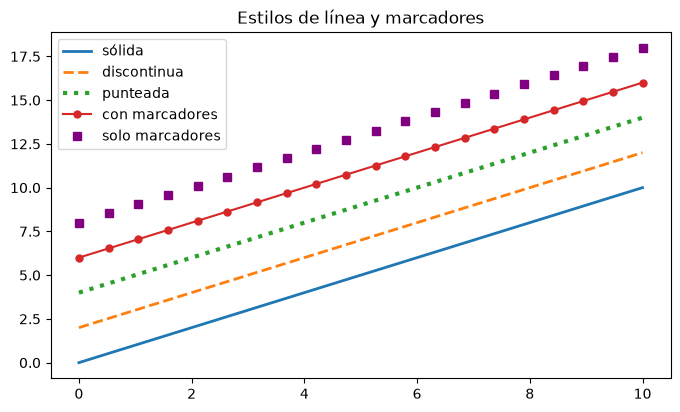

In [5]:
x = np.linspace(0, 10, 20)

fig, ax = plt.subplots()
ax.plot(x, x,       color="tab:blue",   linestyle="-",  linewidth=2,  label="sólida")
ax.plot(x, x + 2,   color="tab:orange", linestyle="--", linewidth=2,  label="discontinua")
ax.plot(x, x + 4,   color="tab:green",  linestyle=":",  linewidth=3,  label="punteada")
ax.plot(x, x + 6,   color="tab:red",    marker="o",     markersize=5, label="con marcadores")
ax.plot(x, x + 8,   color="purple",     marker="s",     linestyle="", label="solo marcadores")
ax.set_title("Estilos de línea y marcadores")
ax.legend()
plt.show()

**Parámetros más usados:**

| Parámetro | Ejemplos |
|---|---|
| `color` | `"red"`, `"tab:blue"`, `"#1f77b4"`, `"C0"`, `"C1"`… |
| `linestyle` | `"-"`, `"--"`, `":"`, `"-."`, `""` (sin línea) |
| `linewidth` | `1`, `2.5`… |
| `marker` | `"o"`, `"s"`, `"^"`, `"x"`, `"+"`, `"."` |
| `alpha` | transparencia, de `0` (invisible) a `1` (opaco) |
| `label` | texto para la leyenda |

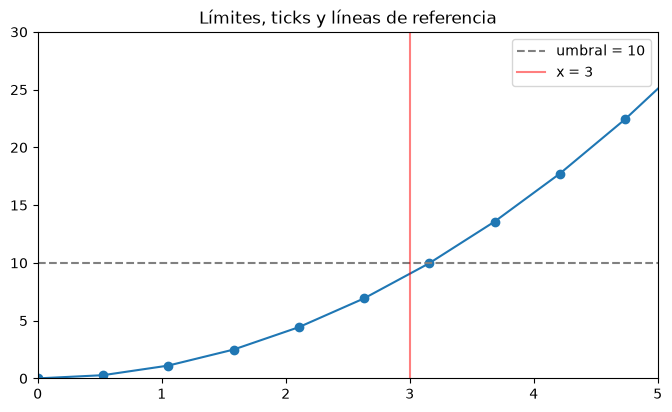

In [6]:
# Controlar los límites y las marcas de los ejes
fig, ax = plt.subplots()
ax.plot(x, x ** 2, marker="o")
ax.set_xlim(0, 5)
ax.set_ylim(0, 30)
ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.axhline(y=10, color="gray", linestyle="--", label="umbral = 10")   # línea horizontal
ax.axvline(x=3, color="red", alpha=0.5, label="x = 3")                # línea vertical
ax.set_title("Límites, ticks y líneas de referencia")
ax.legend()
plt.show()

---
## 4. Tipos de gráficos fundamentales

Cada tipo de gráfico responde a una pregunta distinta:

| Pregunta | Gráfico |
|---|---|
| ¿Cómo evoluciona algo? | **líneas** (`plot`) |
| ¿Qué relación hay entre dos variables? | **dispersión** (`scatter`) |
| ¿Cómo se comparan categorías? | **barras** (`bar`, `barh`) |
| ¿Cómo se distribuye una variable? | **histograma**, **boxplot** (los haremos con seaborn en la sección 7) |

### 4.1 Gráfico de dispersión (`scatter`)

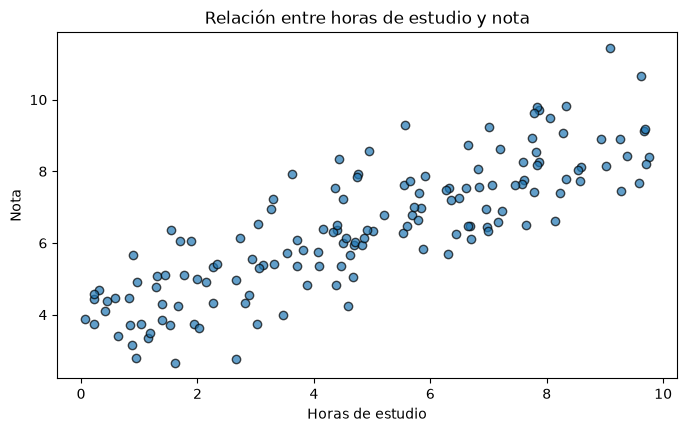

In [7]:
n = 150
horas_estudio = rng.uniform(0, 10, n)
nota = 4 + 0.5 * horas_estudio + rng.normal(0, 1, n)

fig, ax = plt.subplots()
ax.scatter(horas_estudio, nota, alpha=0.7, edgecolor="k")
ax.set_xlabel("Horas de estudio")
ax.set_ylabel("Nota")
ax.set_title("Relación entre horas de estudio y nota")
plt.show()

### 4.2 Gráfico de barras (`bar` / `barh`)

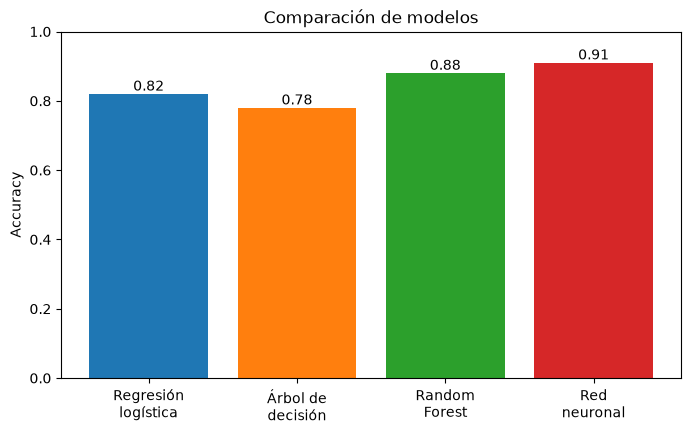

In [8]:
modelos = ["Regresión\nlogística", "Árbol de\ndecisión", "Random\nForest", "Red\nneuronal"]
accuracy = [0.82, 0.78, 0.88, 0.91]

fig, ax = plt.subplots()
barras = ax.bar(modelos, accuracy, color=["C0", "C1", "C2", "C3"])
ax.bar_label(barras, fmt="%.2f")          # escribe el valor encima de cada barra
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
ax.set_title("Comparación de modelos")
plt.show()

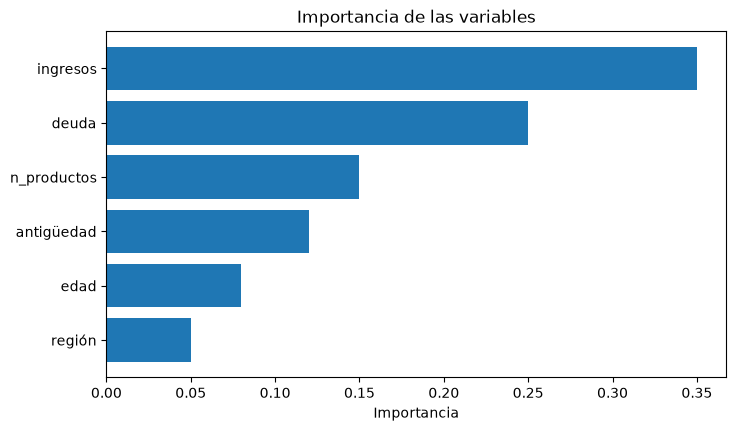

In [9]:
# Barras horizontales: ideales para muchas categorías o nombres largos.
# Ejemplo típico de ML: importancia de variables (feature importance)
features = ["edad", "ingresos", "deuda", "antigüedad", "n_productos", "región"]
importancia = np.array([0.08, 0.35, 0.25, 0.12, 0.15, 0.05])

orden = np.argsort(importancia)           # ordenar de menor a mayor
fig, ax = plt.subplots()
ax.barh(np.array(features)[orden], importancia[orden], color="tab:blue")
ax.set_xlabel("Importancia")
ax.set_title("Importancia de las variables")
plt.show()

### 4.3 Áreas sombreadas (`fill_between`)

Útil para mostrar **incertidumbre** o intervalos de confianza:

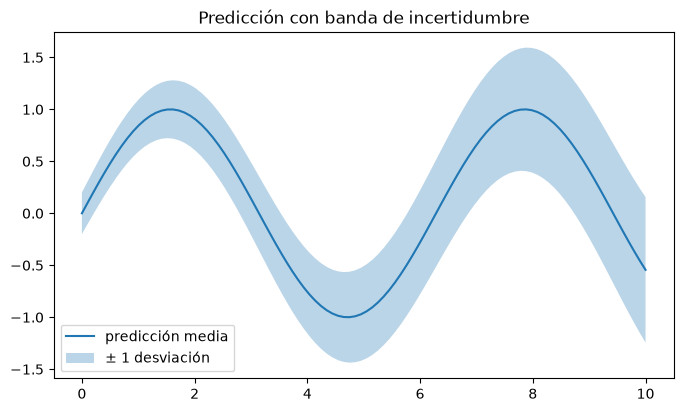

In [10]:
x = np.linspace(0, 10, 100)
media = np.sin(x)
desviacion = 0.2 + 0.05 * x

fig, ax = plt.subplots()
ax.plot(x, media, label="predicción media")
ax.fill_between(x, media - desviacion, media + desviacion, alpha=0.3, label="± 1 desviación")
ax.set_title("Predicción con banda de incertidumbre")
ax.legend()
plt.show()

---
## 5. Varios gráficos en una figura: `subplots`

`plt.subplots(filas, columnas)` devuelve la figura y un **array de NumPy** con los `Axes`.

Forma de axes: (2, 2)


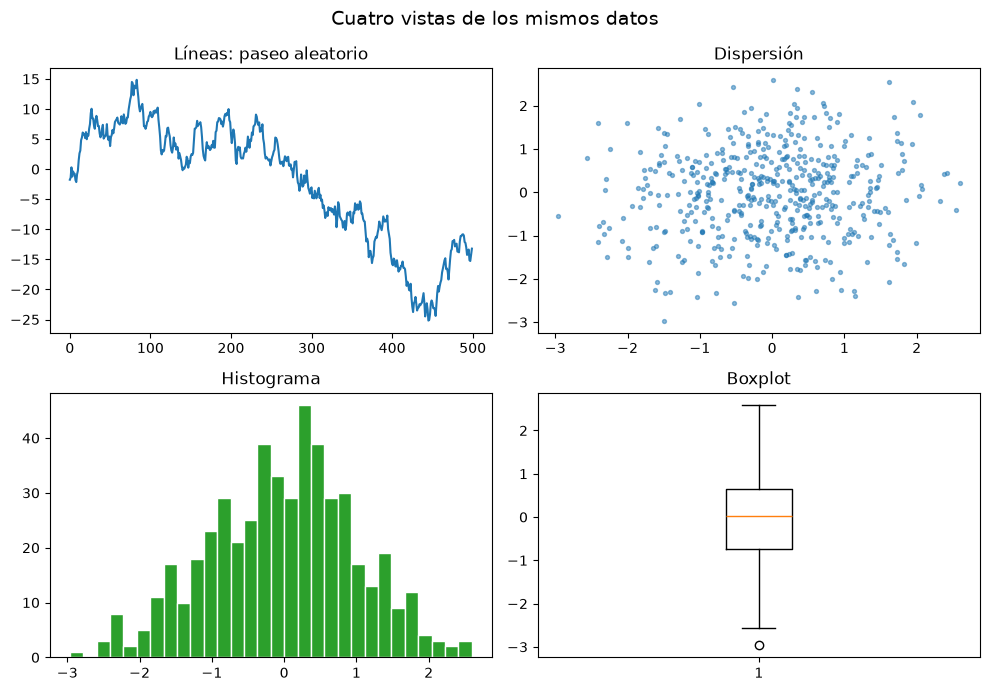

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
print("Forma de axes:", axes.shape)

datos = rng.normal(0, 1, 500)

axes[0, 0].plot(np.cumsum(datos))
axes[0, 0].set_title("Líneas: paseo aleatorio")

axes[0, 1].scatter(datos[:-1], datos[1:], s=8, alpha=0.5)
axes[0, 1].set_title("Dispersión")

axes[1, 0].hist(datos, bins=30, color="tab:green", edgecolor="white")
axes[1, 0].set_title("Histograma")

axes[1, 1].boxplot(datos)
axes[1, 1].set_title("Boxplot")

fig.suptitle("Cuatro vistas de los mismos datos", fontsize=14)
plt.tight_layout()     # ajusta los espacios para que nada se solape
plt.show()

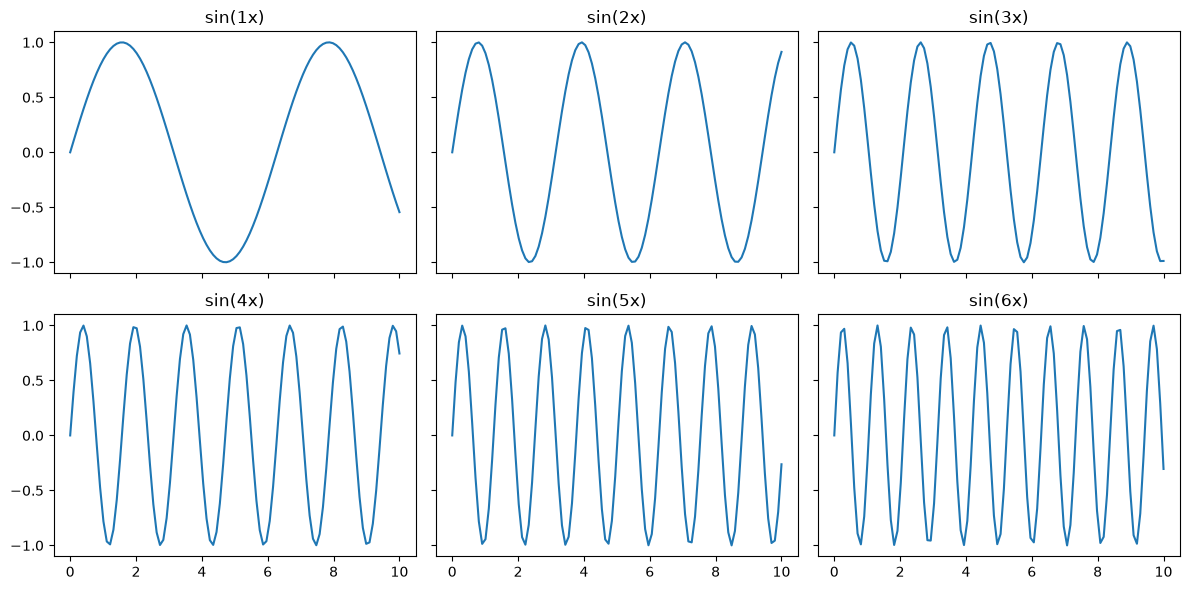

In [12]:
# Recorrer los subplots con un bucle usando axes.flat
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    frecuencia = i + 1
    ax.plot(x, np.sin(frecuencia * x))
    ax.set_title(f"sin({frecuencia}x)")
plt.tight_layout()
plt.show()

> 💡 `sharex=True` / `sharey=True` hacen que todos los subplots compartan la misma escala, lo que facilita compararlos.

---
## 6. Imágenes y matrices: `imshow`

Para una computadora, una imagen es una **matriz de números**. `imshow` dibuja cualquier matriz como una imagen, donde cada valor se convierte en un color.

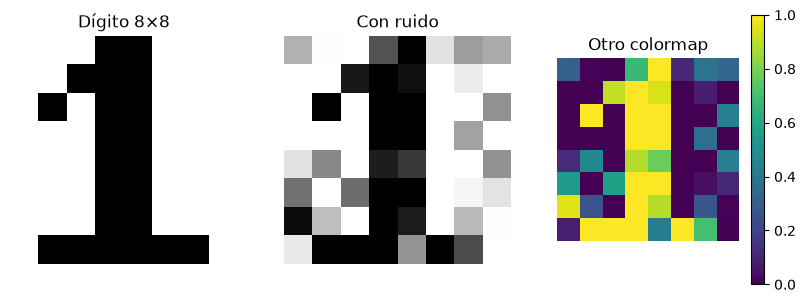

In [13]:
# Creamos a mano una "imagen" de 8x8 que representa el número 1 (como en un dataset de dígitos)
digito = np.array([
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 0, 1, 1, 1, 0, 0, 0],
    [0, 1, 0, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
])

ruidoso = np.clip(digito + rng.normal(0, 0.3, digito.shape), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(digito, cmap="gray_r")
axes[0].set_title("Dígito 8×8")
axes[1].imshow(ruidoso, cmap="gray_r")
axes[1].set_title("Con ruido")
im = axes[2].imshow(ruidoso, cmap="viridis")
axes[2].set_title("Otro colormap")
fig.colorbar(im, ax=axes[2])
for ax in axes:
    ax.axis("off")
plt.show()

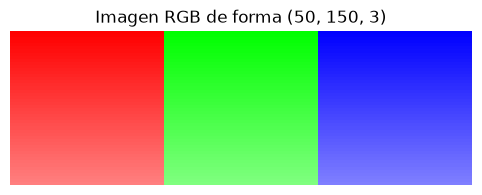

In [14]:
# Una imagen a color es un tensor (alto, ancho, 3) con los canales R, G, B
img = np.zeros((50, 150, 3))
img[:, :50, 0] = 1      # tercio izquierdo: rojo
img[:, 50:100, 1] = 1   # tercio central: verde
img[:, 100:, 2] = 1     # tercio derecho: azul
img += np.linspace(0, 1, 50)[:, None, None] * 0.5   # degradado vertical (broadcasting)
img = np.clip(img, 0, 1)

fig, ax = plt.subplots(figsize=(6, 2))
ax.imshow(img)
ax.set_title(f"Imagen RGB de forma {img.shape}")
ax.axis("off")
plt.show()

---
## 7. Seaborn: gráficos estadísticos en pocas líneas

Hasta ahora hemos construido cada gráfico pieza a pieza. Para **explorar datos**, eso se vuelve repetitivo: separar por grupos, calcular medias, poner colores y leyendas…

**Seaborn** es una librería construida sobre matplotlib y pensada para trabajar directamente con **DataFrames de pandas**:

- le pasas el DataFrame (`data=`) y los **nombres de las columnas** (`x=`, `y=`);
- `hue=` colorea según una variable categórica, y la leyenda sale sola;
- calcula por ti conteos, medias e intervalos.

Como dibuja sobre un `ax` de matplotlib, todo lo que ya sabes (títulos, `subplots`, `savefig`…) sigue funcionando igual. Convención: `import seaborn as sns`.

Usaremos el dataset de viviendas del notebook de pandas:

In [15]:
# Los datos están en la carpeta data/ de la raíz del repo (uv run python scripts/download_data.py)
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
viviendas = pd.read_csv(raiz / "data" / "viviendas.csv")
viviendas.head()

,id,fecha_venta,barrio,metros,habitaciones,antiguedad,garaje,precio
0,1,2022-08-04,Este,127.0,3,6.0,sí,331800.0
1,2,2023-08-12,Norte,82.0,2,44.0,no,241300.0
2,3,2024-10-02,Oeste,101.0,4,13.0,no,265000.0
3,4,2023-06-18,Este,30.0,1,53.0,no,55500.0
4,5,2023-01-17,Centro,55.0,1,43.0,no,171500.0


### 7.1 Distribuciones: `histplot` ⭐

El histograma es el gráfico más importante en la **exploración de datos**: muestra cómo se distribuyen los valores de una variable.

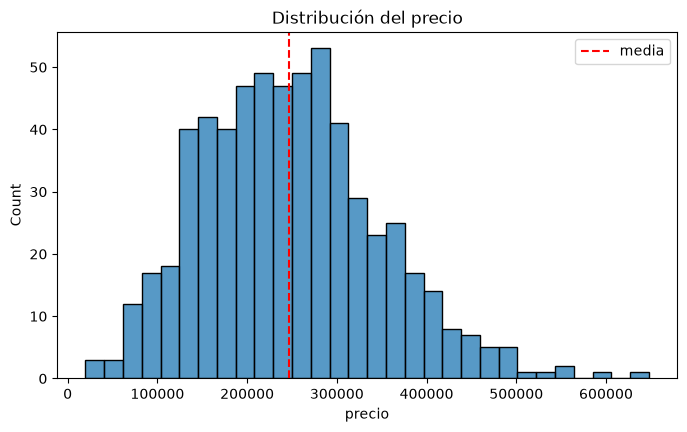

In [16]:
fig, ax = plt.subplots()
sns.histplot(data=viviendas, x="precio", bins=30, ax=ax)
ax.axvline(viviendas["precio"].mean(), color="red", linestyle="--", label="media")
ax.set_title("Distribución del precio")
ax.legend()
plt.show()

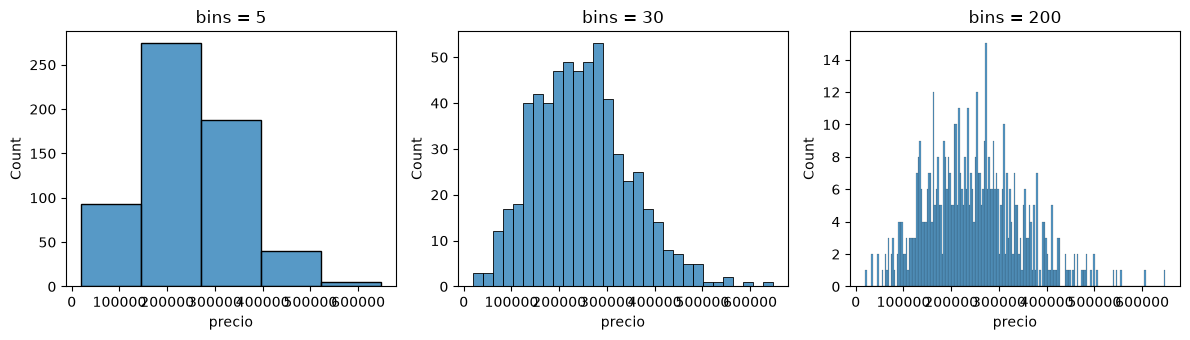

In [17]:
# El número de bins cambia mucho la lectura del histograma
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, bins in zip(axes, [5, 30, 200]):
    sns.histplot(data=viviendas, x="precio", bins=bins, ax=ax)
    ax.set_title(f"bins = {bins}")
plt.tight_layout()
plt.show()

Con `hue=` comparamos la distribución entre grupos. Como los grupos tienen distinto tamaño, usamos `stat="density"` y `common_norm=False` para que cada uno se normalice por separado:

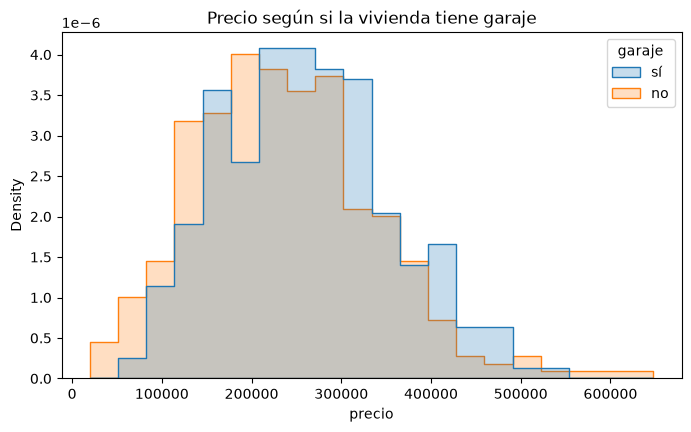

In [18]:
fig, ax = plt.subplots()
sns.histplot(data=viviendas, x="precio", hue="garaje", stat="density", common_norm=False, element="step", ax=ax)
ax.set_title("Precio según si la vivienda tiene garaje")
plt.show()

> 🧠 **En ML**: si una variable es muy asimétrica (como los salarios o los precios), a menudo conviene transformarla con `np.log1p` antes de entrenar un modelo.

### 7.2 Comparar distribuciones: `boxplot`

Resume una distribución en 5 números (mínimo, Q1, mediana, Q3, máximo) y muestra los **valores atípicos** (*outliers*) como puntos sueltos. Con seaborn, un boxplot por cada categoría es una sola línea:

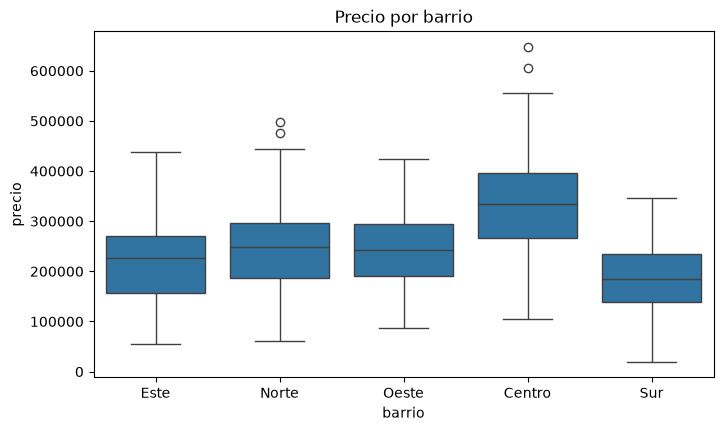

In [19]:
fig, ax = plt.subplots()
sns.boxplot(data=viviendas, x="barrio", y="precio", ax=ax)
ax.set_title("Precio por barrio")
plt.show()

### 7.3 Relación entre variables: `scatterplot`

`hue` (color) y `size` (tamaño) permiten mostrar **4 variables** en un solo gráfico:

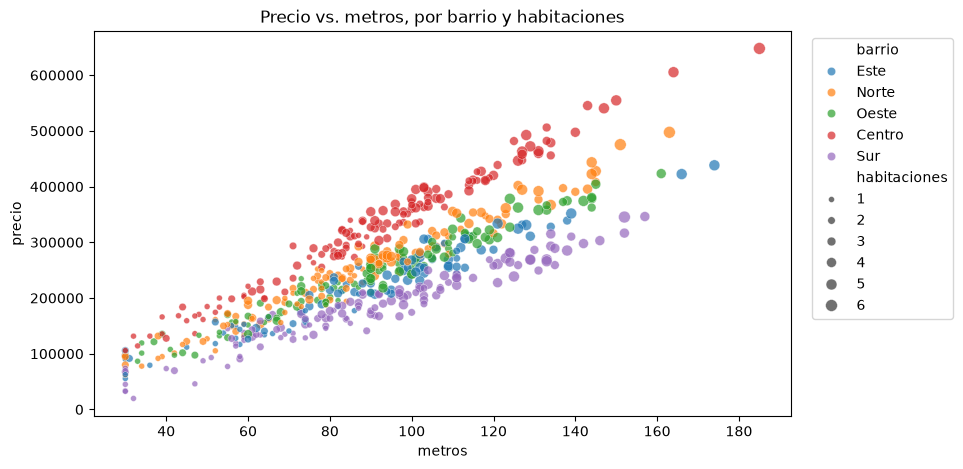

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=viviendas, x="metros", y="precio", hue="barrio", size="habitaciones", alpha=0.7, ax=ax)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")   # leyenda fuera del gráfico
ax.set_title("Precio vs. metros, por barrio y habitaciones")
plt.show()

### 7.4 Comparar categorías: `countplot` y `barplot`

- `countplot` cuenta cuántas filas hay de cada categoría (como `value_counts`).
- `barplot` dibuja la **media** de una variable por categoría (como `groupby(...).mean()`). La línea negra es el **intervalo de confianza**: cuánta incertidumbre hay en esa media.

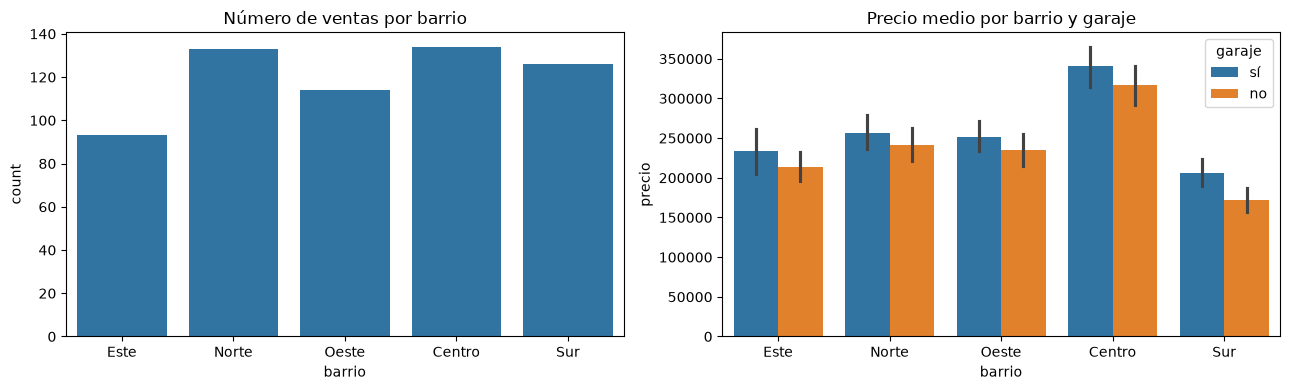

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=viviendas, x="barrio", ax=axes[0])
axes[0].set_title("Número de ventas por barrio")
sns.barplot(data=viviendas, x="barrio", y="precio", hue="garaje", ax=axes[1])
axes[1].set_title("Precio medio por barrio y garaje")
plt.tight_layout()
plt.show()

### 7.5 Mapa de calor de correlaciones: `heatmap`

Un uso muy común en análisis de datos: visualizar la **matriz de correlación** entre variables. Con `annot=True` escribe el valor en cada celda.

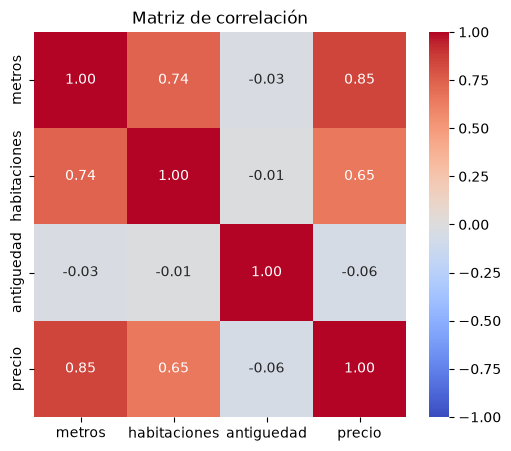

In [22]:
corr = viviendas[["metros", "habitaciones", "antiguedad", "precio"]].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlación")
plt.show()

> 🧠 **Interpretación**: valores cercanos a **+1** (rojo) indican que dos variables suben juntas; cercanos a **−1** (azul), que una sube cuando la otra baja; cercanos a **0**, que no hay relación lineal. Variables muy correlacionadas entre sí aportan información redundante al modelo.

> 💡 **¿Matplotlib o seaborn?** Seaborn para **explorar datos** de un DataFrame (distribuciones, comparaciones, correlaciones). Matplotlib para **todo lo demás** (curvas, contornos, imágenes) y para ajustar los detalles. En la siguiente sección las combinamos.

---
## 8. Gráficos esenciales en Machine Learning 🚀

Vamos a construir un mini-proyecto de **clasificación** de principio a fin y, en cada paso, el gráfico que un profesional de ML haría.

### 8.1 Explorar el dataset

In [23]:
# Dos clases (p. ej. "no compra" / "compra") en función de 2 variables
n_por_clase = 200
clase0 = rng.normal(loc=[2.0, 2.0], scale=[1.2, 1.0], size=(n_por_clase, 2))
clase1 = rng.normal(loc=[4.5, 4.0], scale=[1.0, 1.3], size=(n_por_clase, 2))

X = np.vstack([clase0, clase1])
y = np.array([0] * n_por_clase + [1] * n_por_clase)

# Mezclar y dividir en train / test (como en el notebook de NumPy)
idx = rng.permutation(len(X))
X, y = X[idx], y[idx]
corte = int(0.75 * len(X))
X_train, X_test = X[:corte], X[corte:]
y_train, y_test = y[:corte], y[corte:]
print(X_train.shape, X_test.shape)

(300, 2) (100, 2)


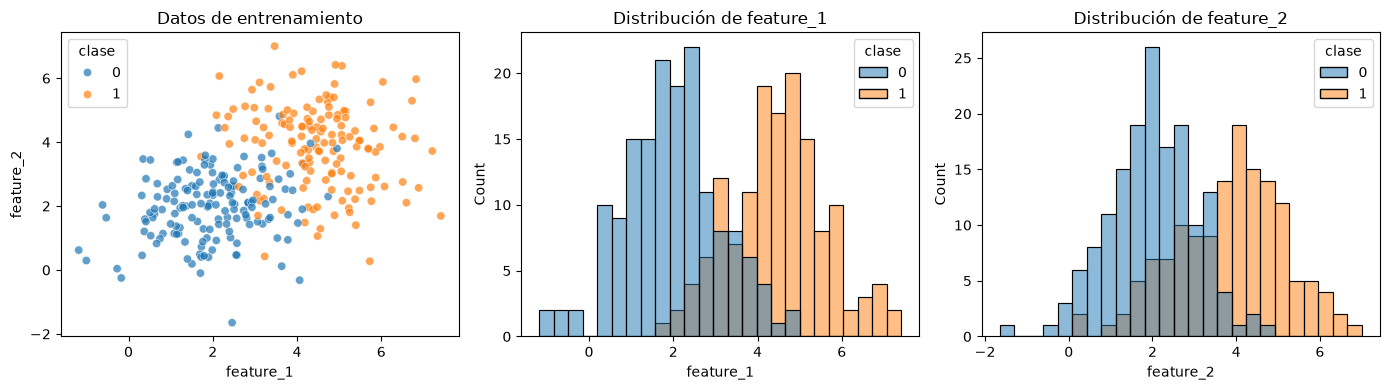

In [24]:
# Pasamos los datos a un DataFrame para usar seaborn
datos = pd.DataFrame(X_train, columns=["feature_1", "feature_2"])
datos["clase"] = y_train

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Dispersión coloreada por clase
sns.scatterplot(data=datos, x="feature_1", y="feature_2", hue="clase", alpha=0.7, ax=axes[0])
axes[0].set_title("Datos de entrenamiento")

# Distribución de cada feature separada por clase
for ax, col in zip(axes[1:], ["feature_1", "feature_2"]):
    sns.histplot(data=datos, x=col, hue="clase", bins=25, ax=ax)
    ax.set_title(f"Distribución de {col}")

plt.tight_layout()
plt.show()

> 🔍 ¿Qué nos dicen? Las clases están **bastante separadas** pero con cierto solapamiento: un modelo lineal debería funcionar razonablemente bien, pero no perfecto.

### 8.2 Curva de aprendizaje (*loss* de train y validación) ⭐

Entrenamos una **regresión logística** con descenso de gradiente (todo en NumPy) y guardamos la pérdida en cada época.

In [25]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


# Estandarizar con las estadísticas de train
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
Xtr = (X_train - mu) / sigma
Xte = (X_test - mu) / sigma

w = np.zeros(2)
b = 0.0
lr = 0.1
loss_train, loss_test = [], []

for epoca in range(150):
    p = sigmoid(Xtr @ w + b)
    w -= lr * Xtr.T @ (p - y_train) / len(y_train)
    b -= lr * np.mean(p - y_train)
    loss_train.append(log_loss(y_train, p))
    loss_test.append(log_loss(y_test, sigmoid(Xte @ w + b)))

print(f"Loss final → train: {loss_train[-1]:.3f} | test: {loss_test[-1]:.3f}")

Loss final → train: 0.251 | test: 0.216


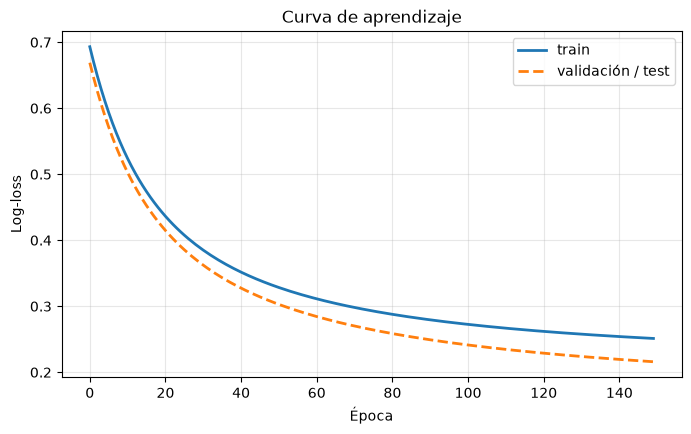

In [26]:
fig, ax = plt.subplots()
ax.plot(loss_train, label="train", linewidth=2)
ax.plot(loss_test, label="validación / test", linewidth=2, linestyle="--")
ax.set_xlabel("Época")
ax.set_ylabel("Log-loss")
ax.set_title("Curva de aprendizaje")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

> 🧠 **Cómo leer una curva de aprendizaje**:
> - Ambas curvas bajan y se estabilizan juntas → ✅ el modelo aprende bien.
> - La de train sigue bajando pero la de validación **sube** → ⚠️ *overfitting* (el modelo memoriza).
> - Ambas se quedan altas → ⚠️ *underfitting* (el modelo es demasiado simple).

### 8.3 Frontera de decisión ⭐

Para ver **qué ha aprendido** un clasificador, evaluamos el modelo en una rejilla de puntos que cubre todo el plano (`np.meshgrid`) y coloreamos cada zona según la predicción.

Forma de la rejilla: (300, 300)


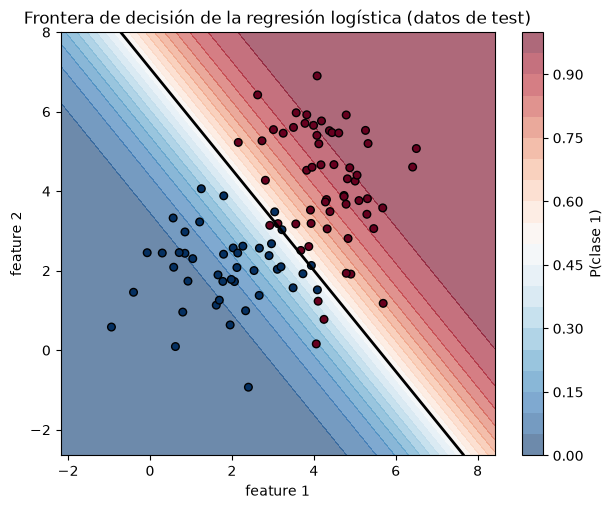

In [27]:
# 1) Crear una rejilla de puntos que cubra el rango de los datos
x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                     np.linspace(x2_min, x2_max, 300))
print("Forma de la rejilla:", xx.shape)

# 2) Predecir la probabilidad para cada punto de la rejilla
rejilla = np.column_stack([xx.ravel(), yy.ravel()])      # (90000, 2)
prob = sigmoid(((rejilla - mu) / sigma) @ w + b).reshape(xx.shape)

# 3) Dibujar
fig, ax = plt.subplots(figsize=(7, 5.5))
cf = ax.contourf(xx, yy, prob, levels=20, cmap="RdBu_r", alpha=0.6)
ax.contour(xx, yy, prob, levels=[0.5], colors="k", linewidths=2)   # frontera: p = 0.5
fig.colorbar(cf, ax=ax, label="P(clase 1)")
ax.scatter(*X_test.T, c=y_test, cmap="RdBu_r", edgecolor="k", s=30)
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.set_title("Frontera de decisión de la regresión logística (datos de test)")
plt.show()

### 8.4 Matriz de confusión

Muestra **cuántas veces acierta y en qué se equivoca** el modelo, desglosado por clase.

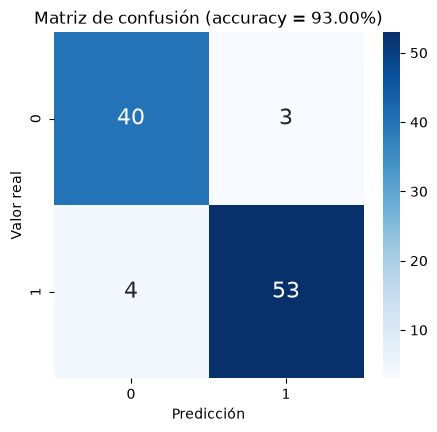

In [28]:
y_pred = (sigmoid(Xte @ w + b) >= 0.5).astype(int)

# crosstab cuenta cada combinación (valor real, predicción): eso es la matriz de confusión
matriz = pd.crosstab(pd.Series(y_test, name="Valor real"), pd.Series(y_pred, name="Predicción"))
accuracy = np.trace(matriz.to_numpy()) / matriz.to_numpy().sum()   # diagonal / total

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", annot_kws={"fontsize": 16}, ax=ax)
ax.set_title(f"Matriz de confusión (accuracy = {accuracy:.2%})")
plt.show()

> 🧠 La **diagonal** son los aciertos. Fuera de la diagonal están los **falsos positivos** (arriba a la derecha) y los **falsos negativos** (abajo a la izquierda). En problemas como el diagnóstico médico, no es lo mismo equivocarse en un sentido que en otro.

### 8.5 *Underfitting* vs. *overfitting*

Ajustamos polinomios de distinto grado a los mismos datos ruidosos. Este gráfico es la mejor manera de **entender intuitivamente** el compromiso sesgo-varianza.

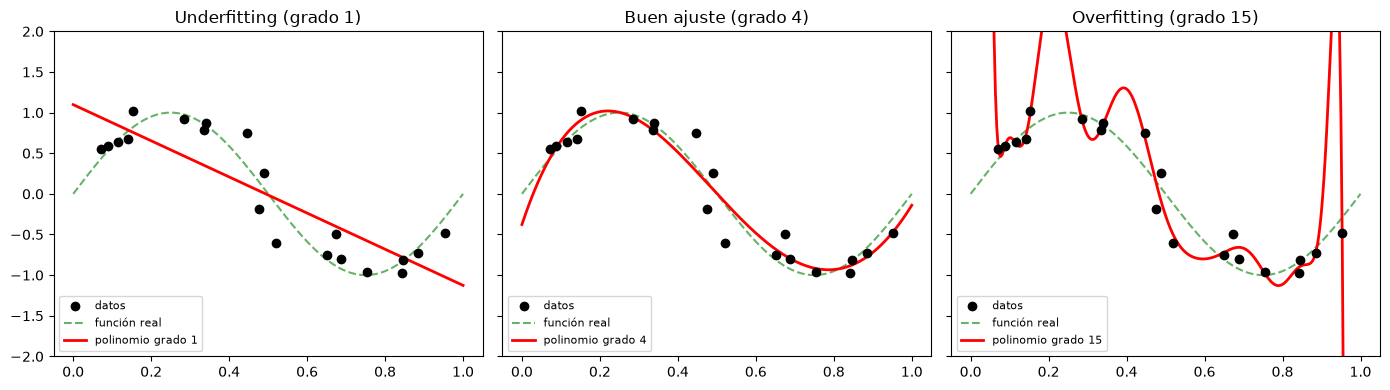

In [29]:
x_datos = np.sort(rng.uniform(0, 1, 20))
y_datos = np.sin(2 * np.pi * x_datos) + rng.normal(0, 0.25, 20)
x_fino = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, grado, titulo in zip(axes, [1, 4, 15], ["Underfitting", "Buen ajuste", "Overfitting"]):
    coef = np.polyfit(x_datos, y_datos, grado)
    ax.scatter(x_datos, y_datos, color="k", zorder=3, label="datos")
    ax.plot(x_fino, np.sin(2 * np.pi * x_fino), "g--", alpha=0.6, label="función real")
    ax.plot(x_fino, np.polyval(coef, x_fino), "r", linewidth=2, label=f"polinomio grado {grado}")
    ax.set_ylim(-2, 2)
    ax.set_title(f"{titulo} (grado {grado})")
    ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### 8.6 Error de train vs. validación según la complejidad del modelo

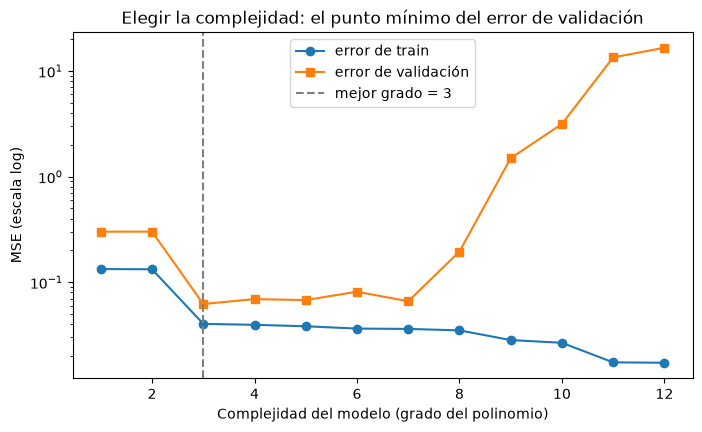

In [30]:
x_val = np.sort(rng.uniform(0, 1, 50))
y_val = np.sin(2 * np.pi * x_val) + rng.normal(0, 0.25, 50)

grados = np.arange(1, 13)
err_train, err_val = [], []
for g in grados:
    coef = np.polyfit(x_datos, y_datos, g)
    err_train.append(np.mean((np.polyval(coef, x_datos) - y_datos) ** 2))
    err_val.append(np.mean((np.polyval(coef, x_val) - y_val) ** 2))

fig, ax = plt.subplots()
ax.plot(grados, err_train, "o-", label="error de train")
ax.plot(grados, err_val, "s-", label="error de validación")
mejor = grados[np.argmin(err_val)]
ax.axvline(mejor, color="gray", linestyle="--", label=f"mejor grado = {mejor}")
ax.set_yscale("log")                 # escala logarítmica: útil cuando los valores varían mucho
ax.set_xlabel("Complejidad del modelo (grado del polinomio)")
ax.set_ylabel("MSE (escala log)")
ax.set_title("Elegir la complejidad: el punto mínimo del error de validación")
ax.legend()
plt.show()

### 8.7 Evaluar una regresión: predicción vs. valor real y residuos

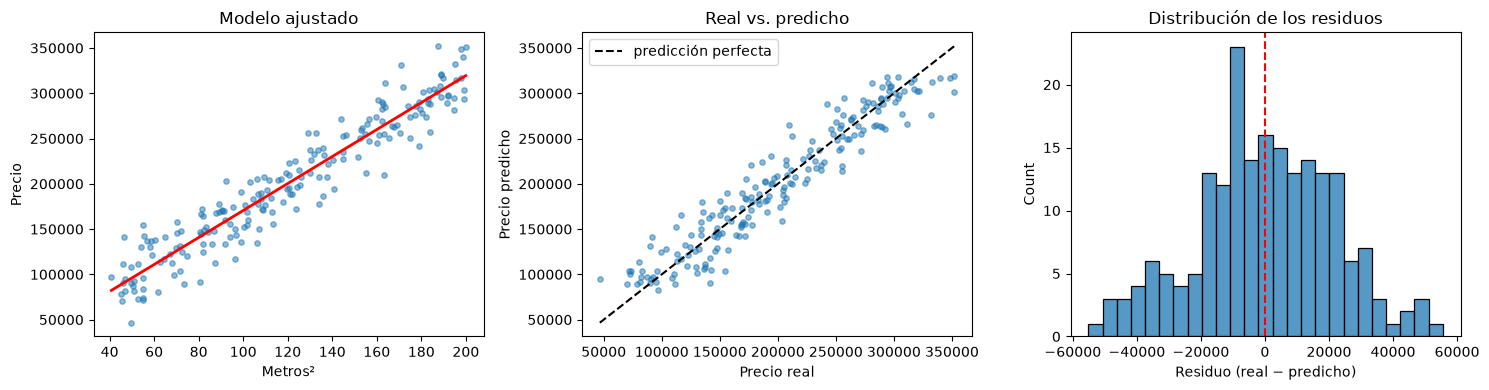

In [31]:
# Regresión lineal sobre datos sintéticos de viviendas
metros = rng.uniform(40, 200, 200)
precio = 1500 * metros + 20000 + rng.normal(0, 20000, 200)

coef = np.polyfit(metros, precio, 1)       # ajuste lineal (grado 1)
pred = np.polyval(coef, metros)
residuos = precio - pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(metros, precio, alpha=0.5, s=15)
orden = np.argsort(metros)
axes[0].plot(metros[orden], pred[orden], "r", linewidth=2)
axes[0].set_xlabel("Metros²")
axes[0].set_ylabel("Precio")
axes[0].set_title("Modelo ajustado")

axes[1].scatter(precio, pred, alpha=0.5, s=15)
lim = [precio.min(), precio.max()]
axes[1].plot(lim, lim, "k--", label="predicción perfecta")
axes[1].set_xlabel("Precio real")
axes[1].set_ylabel("Precio predicho")
axes[1].set_title("Real vs. predicho")
axes[1].legend()

sns.histplot(residuos, bins=25, ax=axes[2])
axes[2].axvline(0, color="r", linestyle="--")
axes[2].set_xlabel("Residuo (real − predicho)")
axes[2].set_title("Distribución de los residuos")

plt.tight_layout()
plt.show()

> 🧠 Un buen modelo de regresión tiene los puntos **pegados a la diagonal** en "real vs. predicho" y unos **residuos centrados en 0** y sin patrones.

---
## 9. Estilos y guardar figuras

### 9.1 Estilos predefinidos

In [32]:
print(plt.style.available[:10], "...")

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6'] ...


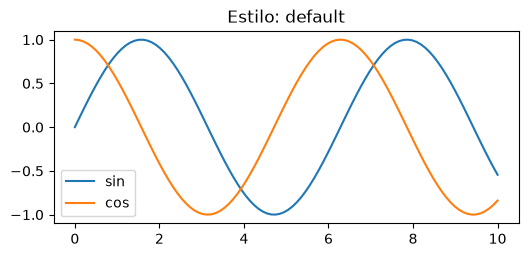

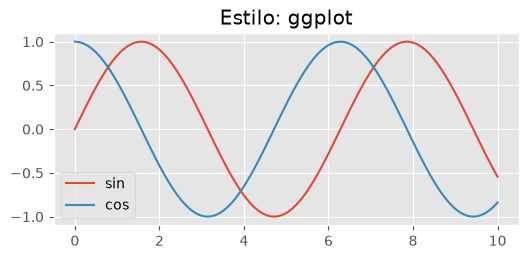

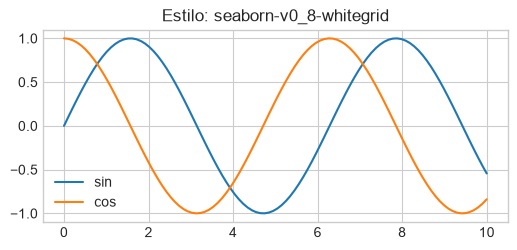

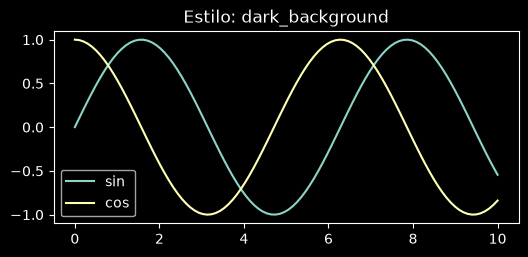

In [33]:
x = np.linspace(0, 10, 100)
for estilo in ["default", "ggplot", "seaborn-v0_8-whitegrid", "dark_background"]:
    with plt.style.context(estilo):          # aplica el estilo solo dentro del bloque
        fig, ax = plt.subplots(figsize=(6, 2.5))
        ax.plot(x, np.sin(x), label="sin")
        ax.plot(x, np.cos(x), label="cos")
        ax.set_title(f"Estilo: {estilo}")
        ax.legend()
        plt.show()

### 9.2 Guardar una figura

Imprescindible para informes y presentaciones. Llama a `savefig` **antes** de `plt.show()`.

Las guardamos en la carpeta `outputs/` de la raíz del repo, que Git ignora, para no mezclar archivos generados con los del curso.

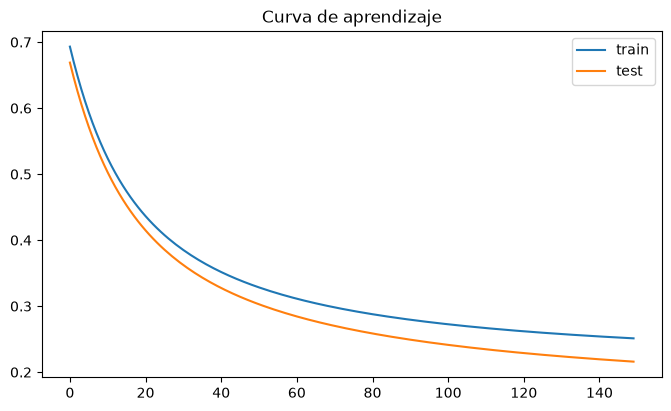

Figuras guardadas en c:\Users\flavs\Documents\ml-course\outputs\figuras


In [34]:
fig, ax = plt.subplots()
ax.plot(loss_train, label="train")
ax.plot(loss_test, label="test")
ax.set_title("Curva de aprendizaje")
ax.legend()

# Raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
carpeta_figuras = raiz / "outputs" / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(carpeta_figuras / "curva_aprendizaje.png", dpi=150, bbox_inches="tight")   # PNG de alta resolución
fig.savefig(carpeta_figuras / "curva_aprendizaje.pdf", bbox_inches="tight")            # vectorial (ideal para papers)
plt.show()
print("Figuras guardadas en", carpeta_figuras)

> 💡 `bbox_inches="tight"` recorta los márgenes sobrantes; `dpi` controla la resolución.

---
## 10. 📋 Chuleta resumen

| Tarea | Código |
|---|---|
| Crear figura y ejes | `fig, ax = plt.subplots(figsize=(8, 4))` |
| Rejilla de gráficos | `fig, axes = plt.subplots(2, 3)` → `axes[i, j]` o `axes.flat` |
| Líneas | `ax.plot(x, y, color=, linestyle=, marker=, label=)` |
| Dispersión | `ax.scatter(x, y, c=, s=, cmap=, alpha=)` |
| Barras | `ax.bar(cats, vals)`, `ax.barh(...)`, `ax.bar_label(...)` |
| Histograma | `sns.histplot(data=df, x="col", hue="cat", bins=30, ax=ax)` |
| Boxplot por grupo | `sns.boxplot(data=df, x="cat", y="col", ax=ax)` |
| Dispersión por grupo | `sns.scatterplot(data=df, x=, y=, hue=, size=, ax=ax)` |
| Conteo / media por grupo | `sns.countplot(data=df, x=)`, `sns.barplot(data=df, x=, y=, hue=)` |
| Mapa de calor | `sns.heatmap(M, annot=True, cmap=, ax=ax)` |
| Imagen / matriz | `ax.imshow(M, cmap=)` + `fig.colorbar(im, ax=ax)` |
| Contornos | `ax.contourf(xx, yy, Z)` (con `np.meshgrid`) |
| Textos | `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel`, `ax.legend()`, `ax.text` |
| Ejes | `ax.set_xlim`, `ax.set_ylim`, `ax.set_yscale("log")`, `ax.grid(alpha=0.3)` |
| Líneas de referencia | `ax.axhline(y)`, `ax.axvline(x)` |
| Ajustar y mostrar | `plt.tight_layout()`, `plt.show()` |
| Guardar | `fig.savefig("archivo.png", dpi=150, bbox_inches="tight")` |

---
### 🎓 Fin del capítulo

Con **NumPy** (calcular), **Pandas** (cargar, explorar y transformar datos) y **Matplotlib** (visualizar) tienes las tres herramientas sobre las que se apoya todo el ecosistema de Machine Learning en Python. ¡Próxima parada: **scikit-learn**! 🚀